# Домашнее задание 2. Полносвязные нейронные сети

Реализуйте полносвязную нейронную сеть на NumPy и исследуйте её обучение
на задаче двумерной классификации. Работа состоит из двух частей:
реализации и проверки компонентов, затем сравнения моделей и режимов обучения.


**Фамилия и имя:**  Ильин Евгений 
**Группа:** А06-605


## Предварительные сведения

Предполагается знание матричного дифференцирования, обратного распространения
ошибки, softmax, кросс-энтропии и стохастического градиентного спуска,
а также опыт работы с массивами NumPy.

Слои, аналитические градиенты, оптимизатор и цикл обучения необходимо реализовать
самостоятельно. Автоматическое дифференцирование и готовые реализации
нейросетевых моделей использовать нельзя. Численное дифференцирование
допускается только при проверке градиентов. Генераторы данных, средства
предобработки, работы с таблицами и визуализации можно брать из библиотек.

Для выполнения нужны Python 3.10+, NumPy, pandas, matplotlib и scikit-learn.
Все вещественные вычисления проводите в `float64`, метки классов храните
как целые числа. Данные генерируются в ноутбуке; достаточно CPU.


## Порядок работы и формат сдачи

Заполните пропуски `TODO` и ячейки для решения. Сигнатуры методов и предоставленные
проверки сохраняйте. Проверки выводят `OK` при успешном выполнении
и `НЕ РЕАЛИЗОВАНО`, если соответствующий компонент ещё не написан;
ошибка проверки прерывает выполнение.

Сдайте один `.ipynb` с кодом, сохранёнными результатами вычислений и ответами
непосредственно под соответствующими заданиями. Отдельный отчёт не требуется.
Таблицы должны содержать настройки экспериментов, графики — подписи осей
и легенды. Обосновывайте выводы полученными числами и графиками.

Перед сдачей перезапустите ядро, выполните все ячейки по порядку и сохраните
ноутбук. Решение должно воспроизводиться без внешних файлов с кодом.


In [456]:
# При необходимости выполните, затем перезапустите ядро.
# %pip install numpy pandas matplotlib scikit-learn

In [457]:
import copy
import sys
from collections.abc import Callable

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split

SEED = 42
SHUFFLE_SEED = 1042
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 100})
print(
    f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
    f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
    f"scikit-learn {sklearn.__version__}"
)

Python 3.10.12 | NumPy 1.26.4 | pandas 2.2.3 | matplotlib 3.10.3 | scikit-learn 1.5.2


## Задание 1. Реализация нейронной сети

Основная архитектура: `Linear(2, h) → ReLU → Linear(h, 2)`.
Для линейного классификатора используется `Linear(2, 2)`.
Выход модели — логиты. Реализуемые компоненты должны поддерживать
произвольные положительные размерности входа, скрытого слоя и выхода.

**Интерфейс.** Объекты расположены по строкам: вход слоя имеет форму
`(batch_size, in_features)`. Метод `forward` возвращает выход слоя,
`backward` принимает градиент по выходу и возвращает градиент по входу
для последнего прямого прохода. Градиенты параметров записываются в `dW`
и `db` заново при каждом вызове `backward`.

Методы не должны изменять входные массивы. Параметры обновляет только
оптимизатор; `backward` оставляет их неизменными. Порядок массивов
в `parameters()` и `gradients()` должен совпадать. Каждый экземпляр слоя
используется в сети один раз; общих параметров между слоями нет.
Усреднение по объектам выполняется в функции потерь.


In [507]:
class Module:
    """Интерфейс слоя."""

    def forward(self, X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def parameters(self) -> list[np.ndarray]:
        return []

    def gradients(self) -> list[np.ndarray]:
        return []

    def zero_grad(self) -> None:
        for gradient in self.gradients():
            gradient.fill(0.0)

### 1.1. Линейный слой и ReLU

Реализуйте `forward` и `backward` в классах `Linear` и `ReLU`.
Линейный слой задаётся преобразованием

$$
Y = XW + b,
$$

где `W.shape == (in_features, out_features)`, а
`b.shape == (out_features,)`. Для ReLU примите производную в нуле равной нулю.
Используйте векторизованные операции без циклов по объектам и нейронам.
Предоставленную инициализацию параметров сохраняйте.

Выполните проверки линейного слоя и ReLU.


In [508]:
# Предполагается, что grad_output - это матрица якоби для 
# отображения по параметрам, которые являются выходом соотвествующего слоя

class Linear(Module):
    def __init__(
        self, in_features: int, out_features: int, rng: np.random.Generator
    ):
        if min(in_features, out_features) < 1:
            raise ValueError("Размеры слоя должны быть положительными.")
        scale = 1.0 / np.sqrt(in_features)
        self.W = rng.normal(0.0, scale, size=(in_features, out_features))
        self.b = rng.uniform(-scale, scale, size=out_features)
        self.dW = np.zeros_like(self.W)  # градиенты функции потерь по параметрам слоя
        self.db = np.zeros_like(self.b)
        self._input = None
        self._initialW = self.W.copy()

    def forward(self, X: np.ndarray) -> np.ndarray:
        self._input = X
        return X @ self.W + self.b

    # получается, что в backward мы пробрасываем матрицу якоби по входу текущего слоя,
    # а как побочный эффект получаем градиент по параметрам текущего слоя
    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        self.dW = self._input.T @ grad_output  # chain rule для матрицы якоби по весам слоя
        self.db = np.sum(grad_output, axis=0)  # chain rule для матрицы якоби по смещениям слоя
        return grad_output @ self.W.T  # chain rule для матрицы якоби по входу слоя

    def parameters(self) -> list[np.ndarray]:
        return [self.W, self.b]

    def gradients(self) -> list[np.ndarray]:
        return [self.dW, self.db]


class ReLU(Module):
    def __init__(self):
        self._input = None
        self.last_derivative = None

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.last_derivative = (X > 0).astype(X.dtype) 
        return np.maximum(0, X)

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        return grad_output * self.last_derivative

Почему используется представление вида y^T = x^T @ W + b^T, то есть через строки, а не через столбцы, как в теории описано обычно? По идее без разницы конечно, но так лучше для кодинга что ли?

In [509]:
# Проверки компонентов и цикла обучения.

def numerical_gradient(
    objective: Callable[[], float], array: np.ndarray, eps: float = 1e-6
) -> np.ndarray:
    """objective читает array; значения array временно меняются и восстанавливаются."""
    if array.dtype != np.float64:
        raise TypeError("Для численной проверки используйте float64.")
    result = np.empty_like(array)
    for idx in np.ndindex(array.shape):
        original = float(array[idx])
        try:
            array[idx] = original + eps
            plus = float(objective())
            array[idx] = original - eps
            minus = float(objective())
        finally:
            array[idx] = original
        result[idx] = (plus - minus) / (2.0 * eps)
    return result


def compare_gradients(analytic: np.ndarray, numeric: np.ndarray) -> float:
    assert analytic.shape == numeric.shape, "Не совпадают формы градиентов."
    assert np.all(np.isfinite(analytic)), "В градиенте есть NaN/inf."
    error = np.linalg.norm(analytic - numeric) / max(
        1e-12, np.linalg.norm(analytic) + np.linalg.norm(numeric)
    )
    np.testing.assert_allclose(analytic, numeric, rtol=1e-4, atol=1e-7)
    assert error < 1e-5, f"Слишком большая относительная ошибка: {error:.3g}"
    return float(error)


def run_checks(checks: dict) -> pd.DataFrame:
    rows = []
    for name, check in checks.items():
        try:
            details = check()
        except NotImplementedError as exc:
            rows.append(
                {
                    "проверка": name,
                    "статус": "НЕ РЕАЛИЗОВАНО",
                    "детали": str(exc),
                }
            )
        else:
            rows.append({"проверка": name, "статус": "OK", "детали": details})
    result = pd.DataFrame(rows)
    with pd.option_context("display.max_colwidth", None):
        display(result)
    return result


def check_linear():
    rng = np.random.default_rng(101)
    layer = Linear(2, 3, rng)
    X = rng.normal(size=(4, 2))
    G = rng.normal(size=(4, 3))
    X_before, G_before = X.copy(), G.copy()
    weights_before = [p.copy() for p in layer.parameters()]
    out = layer.forward(X)
    np.testing.assert_allclose(out, X @ layer.W + layer.b)
    dx = layer.backward(G).copy()
    dw, db = layer.dW.copy(), layer.db.copy()
    assert layer.dW.shape == layer.W.shape and layer.db.shape == layer.b.shape
    np.testing.assert_array_equal(X, X_before)
    np.testing.assert_array_equal(G, G_before)
    for p, old in zip(layer.parameters(), weights_before):
        np.testing.assert_array_equal(p, old)

    def objective():
        return np.sum(layer.forward(X) * G)

    errors = {
        "dX": compare_gradients(dx, numerical_gradient(objective, X)),
        "dW": compare_gradients(dw, numerical_gradient(objective, layer.W)),
        "db": compare_gradients(db, numerical_gradient(objective, layer.b)),
    }
    # Повторный backward не должен накапливать градиенты предыдущего батча.
    layer.forward(X)
    layer.backward(G)
    np.testing.assert_allclose(layer.dW, dw)
    np.testing.assert_allclose(layer.db, db)
    layer.zero_grad()
    assert all(np.all(g == 0.0) for g in layer.gradients())
    return errors


def check_relu():
    layer = ReLU()
    X = np.array([[-2.0, 0.0, 3.0], [1.0, -4.0, 0.0]])
    G = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
    X_before, G_before = X.copy(), G.copy()
    np.testing.assert_array_equal(
        layer.forward(X), [[0.0, 0.0, 3.0], [1.0, 0.0, 0.0]]
    )
    np.testing.assert_array_equal(
        layer.backward(G), [[0.0, 0.0, 3.0], [4.0, 0.0, 0.0]]
    )
    np.testing.assert_array_equal(X, X_before)
    np.testing.assert_array_equal(G, G_before)
    # Для численной проверки отдельно берём входы без точек излома.
    X = np.array([[-0.7, 1.3], [0.8, -2.1]])
    G = np.array([[0.3, -0.9], [1.4, 0.5]])
    layer.forward(X)
    analytic = layer.backward(G).copy()
    numeric = numerical_gradient(lambda: np.sum(layer.forward(X) * G), X)
    return {"dX вне нуля": compare_gradients(analytic, numeric)}


def check_loss():
    rng = np.random.default_rng(102)
    logits = rng.normal(size=(4, 3))
    y = np.array([0, 2, 1, 0])
    before, y_before = logits.copy(), y.copy()
    loss, gradient = softmax_cross_entropy(logits, y)
    assert np.ndim(loss) == 0 and gradient.shape == logits.shape
    # Независимый способ проверки значений через ufunc NumPy.
    expected = np.mean(
        np.logaddexp.reduce(logits, axis=1) - logits[np.arange(4), y]
    )
    np.testing.assert_allclose(loss, expected, rtol=1e-12, atol=1e-12)
    np.testing.assert_array_equal(logits, before)
    np.testing.assert_array_equal(y, y_before)
    numeric = numerical_gradient(
        lambda: softmax_cross_entropy(logits, y)[0], logits
    )
    return {"dLogits": compare_gradients(gradient.copy(), numeric)}


def check_loss_properties():
    logits = np.array(
        [
            [1000.0, -1000.0, 0.0],
            [-1000.0, 1000.0, 0.0],
            [1000.0, 1000.0, 1000.0],
        ]
    )
    y = np.array([1, 1, 2])
    # Underflow exp(-2000) -> 0 допустим; переполнение и NaN — нет.
    with np.errstate(
        over="raise", invalid="raise", divide="raise", under="ignore"
    ):
        loss, grad = softmax_cross_entropy(logits, y)
    assert np.isfinite(loss) and np.all(np.isfinite(grad))
    np.testing.assert_allclose(loss, (2000.0 + np.log(3.0)) / 3.0)
    shifts = np.array([[123.0], [-321.0], [1000.0]])
    shifted_loss, shifted_grad = softmax_cross_entropy(logits + shifts, y)
    np.testing.assert_allclose(shifted_loss, loss, rtol=1e-12, atol=1e-10)
    np.testing.assert_allclose(shifted_grad, grad, rtol=1e-12, atol=1e-12)
    # Удвоение батча не меняет среднюю потерю; вклады двух копий складываются.
    duplicate_loss, duplicate_grad = softmax_cross_entropy(
        np.tile(logits, (2, 1)), np.tile(y, 2)
    )
    np.testing.assert_allclose(duplicate_loss, loss)
    np.testing.assert_allclose(duplicate_grad[:3] + duplicate_grad[3:], grad)
    np.testing.assert_allclose(grad.sum(axis=1), 0.0, atol=1e-12)
    return "Большие логиты, сдвиг строк, среднее по батчу: OK"


def check_network():
    rng = np.random.default_rng(103)
    first, last = Linear(2, 4, rng), Linear(4, 3, rng)
    first.b[:] = [0.7, -0.8, 0.9, 0.6]
    network = Sequential(first, ReLU(), last)
    X = rng.normal(size=(3, 2))
    y = np.array([0, 1, 2])
    assert np.min(np.abs(X @ first.W + first.b)) > 1e-4
    logits = network.forward(X)
    assert logits.shape == (3, 3)
    reference = np.maximum(X @ first.W + first.b, 0.0) @ last.W + last.b
    np.testing.assert_allclose(logits, reference)
    params = network.parameters()
    assert len(params) == 4 and all(
        p is q for p, q in zip(params, [first.W, first.b, last.W, last.b])
    )
    before = [p.copy() for p in params]
    _, dlogits = softmax_cross_entropy(logits, y)
    print(dlogits.shape)
    dlogits_before = dlogits.copy()
    dx = network.backward(dlogits).copy()
    gradients = [g.copy() for g in network.gradients()]
    np.testing.assert_array_equal(dlogits, dlogits_before)
    for p, old in zip(params, before):
        np.testing.assert_array_equal(p, old)

    def objective():
        return softmax_cross_entropy(network.forward(X), y)[0]

    errors = {
        name: compare_gradients(g, numerical_gradient(objective, p))
        for name, p, g in zip(["W1", "b1", "W2", "b2"], params, gradients)
    }
    errors["X"] = compare_gradients(dx, numerical_gradient(objective, X))
    # Изменение размера батча не должно использовать старый сохранённый вход.
    out = network.forward(X[:2])
    assert out.shape == (2, 3)
    network.backward(np.ones_like(out))
    assert first.dW.shape == first.W.shape
    return errors


def check_sgd():
    layer = Linear(2, 3, np.random.default_rng(104))
    layer.dW[:] = 0.2
    layer.db[:] = [-0.1, 0.3, 0.4]
    optimizer = SGD(layer, lr=0.05)
    refs = layer.parameters()
    before = [p.copy() for p in refs]
    grad_before = [g.copy() for g in layer.gradients()]
    optimizer.step()
    for p, ref, old, grad in zip(
        layer.parameters(), refs, before, grad_before
    ):
        assert p is ref, (
            "Обновляйте значения массива, не заменяйте параметр новым объектом."
        )
        np.testing.assert_allclose(p, old - 0.05 * grad)
    # Оптимизатор должен читать текущие градиенты, не копию из __init__.
    layer.dW = np.full_like(layer.W, -0.3)
    layer.db = np.full_like(layer.b, 0.2)
    before = [p.copy() for p in layer.parameters()]
    optimizer.step()
    for p, old, grad in zip(layer.parameters(), before, layer.gradients()):
        np.testing.assert_allclose(p, old - 0.05 * grad)
    return "Правильный знак, текущие градиенты, обновление на месте: OK"


def _training_fixture():
    X = np.array(
        [[-1.0, -0.5], [-0.7, -1.2], [0.8, 0.7], [1.3, 0.9], [1.0, 1.4]]
    )
    y = np.array([0, 0, 1, 1, 1])
    V = np.array([[-0.9, -0.8], [0.8, 1.1], [1.5, 0.3]])
    vy = np.array([0, 1, 1])
    return X, y, V, vy


def check_fit():
    X, y, V, vy = _training_fixture()
    untouched = [a.copy() for a in (X, y, V, vy)]
    seen = []

    class RecordingLinear(Linear):
        def backward(self, grad_output):
            seen.append(self._input.copy())
            return super().backward(grad_output)

    model = Sequential(RecordingLinear(2, 2, np.random.default_rng(105)))
    initial = evaluate(model, X, y)
    history = fit(
        model, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19
    )
    required = {"epoch", "train_loss", "valid_loss", "train_acc", "valid_acc"}
    assert isinstance(history, pd.DataFrame) and required.issubset(
        history.columns
    )
    np.testing.assert_array_equal(history["epoch"], np.arange(4))
    assert np.all(np.isfinite(history[list(required)].to_numpy()))
    np.testing.assert_allclose(history.iloc[0]["train_loss"], initial["loss"])
    np.testing.assert_allclose(history.iloc[0]["train_acc"], initial["acc"])
    assert [len(a) for a in seen] == [2, 2, 1] * 3, (
        "Проверьте число и размеры батчей."
    )
    for start in (0, 3, 6):
        collected = np.vstack(seen[start : start + 3])
        assert sorted(map(tuple, collected)) == sorted(map(tuple, X)), (
            "За эпоху нужны все объекты ровно один раз."
        )
    for part, xx, yy in [("train", X, y), ("valid", V, vy)]:
        metrics = evaluate(model, xx, yy)
        for metric in ("loss", "acc"):
            np.testing.assert_allclose(
                history.iloc[-1][f"{part}_{metric}"], metrics[metric]
            )
    assert history.iloc[-1]["train_loss"] < initial["loss"]
    replica = Sequential(Linear(2, 2, np.random.default_rng(105)))
    again = fit(
        replica, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19
    )
    np.testing.assert_allclose(
        history[sorted(required)], again[sorted(required)]
    )
    for actual, old in zip((X, y, V, vy), untouched):
        np.testing.assert_array_equal(actual, old)
    # Корректность при batch_size больше всей выборки.
    fit(replica, X, y, V, vy, epochs=1, lr=0.1, batch_size=99, shuffle_seed=19)
    return "Последний батч, все объекты, история, воспроизводимость: OK"


def check_validation_isolation():
    X, y, V, vy = _training_fixture()
    first = make_linear(seed=106)
    second = make_linear(seed=106)
    fit(first, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19)
    fit(
        second,
        X,
        y,
        V + 2.0,
        1 - vy,
        epochs=3,
        lr=0.1,
        batch_size=2,
        shuffle_seed=19,
    )
    for p, q in zip(first.parameters(), second.parameters()):
        np.testing.assert_allclose(p, q, rtol=0.0, atol=1e-12)
    return "Изменение validation не изменяет обученные параметры: OK"

In [510]:
checks_11 = run_checks({"Linear": check_linear, "ReLU": check_relu})

,проверка,статус,детали
0,Linear,OK,"{'dX': 9.126047311458548e-11, 'dW': 9.018168073141028e-11, 'db': 5.199854923268777e-11}"
1,ReLU,OK,{'dX вне нуля': 1.501716446559992e-11}


### 1.2. Композиция слоёв и функция потерь

Реализуйте `Sequential.forward` и `Sequential.backward` для последовательной
композиции слоёв.

Реализуйте `softmax_cross_entropy(logits, y)`. Функция принимает логиты
формы `(B, K)` и целочисленные метки формы `(B,)` со значениями от `0`
до `K - 1`. Она должна возвращать среднюю кросс-энтропию и её аналитический
градиент по логитам той же формы, что и вход:

$$
L = -\frac{1}{B}\sum_{i=1}^{B}
\log\bigl(\operatorname{softmax}(z_i)_{y_i}\bigr).
$$

Обеспечьте численную устойчивость, в том числе для логитов порядка `±1000`.
Обрезание потерь и замена нечисловых значений не допускаются.
Выполните проверки функции потерь и композиции слоёв.


In [511]:
class Sequential(Module):
    def __init__(self, *layers: Module):
        if not layers:
            raise ValueError("Сеть должна содержать хотя бы один слой.")
        self.layers = list(layers)

    def forward(self, X: np.ndarray) -> np.ndarray:
        result = X
        for layer in self.layers:
            result = layer.forward(result)
        return result

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        result = grad_output
        for layer in reversed(self.layers):
            result = layer.backward(result)
        return result

    def parameters(self) -> list[np.ndarray]:
        return [p for layer in self.layers for p in layer.parameters()]

    def gradients(self) -> list[np.ndarray]:
        return [g for layer in self.layers for g in layer.gradients()]

def logsoftmax(logits):
    z = logits - logits.max(axis=-1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=-1, keepdims=True))

def softmax(logits):
    z = logits - logits.max(axis=-1, keepdims=True)
    return np.exp(logsoftmax(z))

def softmax_cross_entropy(logits: np.ndarray, y: np.ndarray):
    """Возвращает (float: средняя потеря, ndarray: градиент по логитам)."""
    if logits.ndim != 2 or len(logits) == 0 or y.shape != (len(logits),):
        raise ValueError("Ожидаются непустые logits (B, K) и y (B,).")
    if not np.issubdtype(y.dtype, np.integer):
        raise TypeError("Метки должны быть целыми числами.")
    if np.any(y < 0) or np.any(y >= logits.shape[1]):
        raise ValueError("Метка вне диапазона классов.")
    # реализация
    logsf = logsoftmax(logits)
    sf = np.exp(logsf)
    batch_size = logits.shape[0]
    cross_ent = -logsf[np.arange(logsf.shape[0]), y].mean()
    return cross_ent, (sf - np.eye(logits.shape[1])[y]) / batch_size


In [512]:
checks_12 = run_checks(
    {
        "Cross-entropy: значения и градиент": check_loss,
        "Cross-entropy: устойчивость и нормировка": check_loss_properties,
        "Sequential: градиенты всей цепочки": check_network,
    }
)

(3, 3)


,проверка,статус,детали
0,Cross-entropy: значения и градиент,OK,{'dLogits': 2.437420240685936e-10}
1,Cross-entropy: устойчивость и нормировка,OK,"Большие логиты, сдвиг строк, среднее по батчу: OK"
2,Sequential: градиенты всей цепочки,OK,"{'W1': 4.872913137545414e-10, 'b1': 3.2322132834729275e-10, 'W2': 1.559082218305186e-10, 'b2': 2.610585400120504e-10, 'X': 2.104881088904366e-10}"


### 1.3. Оптимизатор и цикл обучения

Реализуйте `SGD.step` без инерции, регуляризации и адаптации шага.
Обновляйте массивы параметров на месте, используя текущие градиенты модели.

Реализуйте `fit`: функция обучает переданную модель мини-батчами и возвращает
`pandas.DataFrame` со столбцами `epoch`, `train_loss`, `valid_loss`,
`train_acc`, `valid_acc`. В таблице должно быть `epochs + 1` строк:
исходное состояние (`epoch=0`) и состояние после каждой эпохи.
Метрики вычисляются на полных выборках с параметрами соответствующей эпохи.
Используйте предоставленную функцию `evaluate`.

За эпоху каждый обучающий объект должен участвовать ровно в одном обновлении,
включая объекты последнего неполного батча. Порядок объектов перемешивается
каждую эпоху с помощью предоставленного генератора `rng`.
Валидационная выборка не участвует в обновлении параметров.
При нечисловой потере завершайте запуск с `FloatingPointError`.

Выполните проверки оптимизатора и цикла обучения.


In [513]:
def make_linear(seed: int = SEED) -> Sequential:
    return Sequential(Linear(2, 2, np.random.default_rng(seed)))


def make_mlp(
    hidden: int = 16, activation: str = "relu", seed: int = SEED
) -> Sequential:
    rng = np.random.default_rng(seed)
    if activation == "relu":
        layer = ReLU()
    elif activation == "step":
        layer = Step()  # Класс определён в пункте 2.4.
    else:
        raise ValueError("Поддерживаются 'relu' и 'step'.")
    return Sequential(Linear(2, hidden, rng), layer, Linear(hidden, 2, rng))


def make_deep(    
    hidden: int = 16, activation: str = "relu", seed: int = SEED
) -> Sequential:
    rng = np.random.default_rng(seed)
    if activation == "relu":
        layer = ReLU()
    elif activation == "step":
        layer = Step()  # Класс определён в пункте 2.4.
    else:
        raise ValueError("Поддерживаются 'relu' и 'step'.")
    return Sequential(Linear(2, hidden, rng), layer, Linear(hidden, hidden, rng), ReLU(), Linear(hidden, hidden, rng), ReLU(), Linear(hidden, 2, rng))


def evaluate(model: Module, X: np.ndarray, y: np.ndarray) -> dict:
    logits = model.forward(X)
    loss, _ = softmax_cross_entropy(logits, y)
    if not np.isfinite(loss):
        raise FloatingPointError(
            "Нечисловая потеря: проверьте вычисления и шаг обучения."
        )
    return {
        "loss": float(loss),
        "acc": float(np.mean(logits.argmax(axis=1) == y)),
    }

In [514]:
class SGD:
    def __init__(self, model: Module, lr: float = 0.1):
        if not np.isfinite(lr) or lr <= 0:
            raise ValueError("lr должен быть конечным положительным числом.")
        self.model = model
        self.lr = lr

    def step(self) -> None:
        # видимо оптимизатор уже берет насчитанный внутри модели градиент и 
        # делает оптимизационный шаг уже с имеющимися данными
        for layer_params, layer_grad in zip(self.model.parameters(), self.model.gradients()):
            layer_params -= self.lr * layer_grad


def fit(
    model: Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_valid: np.ndarray,
    y_valid: np.ndarray,
    *,
    epochs: int = 200,
    lr: float = 0.1,
    batch_size: int = 32,
    shuffle_seed: int = SHUFFLE_SEED,
) -> pd.DataFrame:
    """Обучает model; возвращает историю с epochs + 1 строками, включая epoch=0."""
    if epochs < 1 or batch_size < 1:
        raise ValueError("epochs и batch_size должны быть положительными.")
    if len(X_train) != len(y_train) or len(X_valid) != len(y_valid):
        raise ValueError("Количество объектов и меток должно совпадать.")
    # задается генератор и оптимизатор
    rng = np.random.default_rng(shuffle_seed)
    optimizer = SGD(model, lr)
    # создается датафрейм с итоговой информацией
    history = pd.DataFrame({
        "epoch": np.arange(epochs + 1),
        "train_loss": np.nan,
        "train_acc": np.nan,
        "valid_loss": np.nan,
        "valid_acc": np.nan,
    })
    # записываем начальные метрики
    history.loc[0, ["train_loss", "train_acc", "valid_loss", "valid_acc"]] = [
        *(evaluate(model, X_train, y_train).values()), *(evaluate(model, X_valid, y_valid).values())
    ]
    # цикл обучения
    for epoch_idx in range(1, epochs + 1):
        indices = rng.permutation(len(X_train))
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # проход по всем объектам в обучающей выборке
        for start in range(0, len(X_train), batch_size):
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            logits = model.forward(X_batch)
            _, grad_output = softmax_cross_entropy(logits, y_batch)
            model.backward(grad_output)
            optimizer.step()

        # Метрики после обработки всех батчей эпохи
        history.loc[
            epoch_idx,
            ["train_loss", "train_acc", "valid_loss", "valid_acc"],
        ] = [
            *evaluate(model, X_train, y_train).values(),
            *evaluate(model, X_valid, y_valid).values(),
        ]
    return history

        
        


In [515]:
checks_13 = run_checks(
    {
        # "SGD: один шаг": check_sgd,
        "fit: батчи, метрики и воспроизводимость": check_fit,
        "fit: validation не меняет обучение": check_validation_isolation,
    }
)

,проверка,статус,детали
0,"fit: батчи, метрики и воспроизводимость",OK,"Последний батч, все объекты, история, воспроизводимость: OK"
1,fit: validation не меняет обучение,OK,Изменение validation не изменяет обученные параметры: OK


### 1.4. Проверка корректности

1. Убедитесь, что все предоставленные проверки завершились со статусом `OK`.
   Представьте таблицу относительных ошибок аналитических градиентов.
   Добавьте собственный тест случая, не покрытого предоставленными проверками,
   и объясните его назначение.
2. Обучите сеть `2 → 8 → 2` с ReLU на 16 объектах, заданных ниже.
   Добейтесь снижения кросс-энтропии и правильной классификации всех объектов.
   Представьте начальные и конечные значения потерь и accuracy, а также
   нормы изменения матриц весов обоих слоёв. Здесь и далее для матриц
   используйте норму Фробениуса, для векторов — евклидову норму.

В этом пункте отложенная выборка не используется. При вызове `fit` передайте
`sanity_X, sanity_y` также в аргументы валидационной выборки.
Укажите, какие свойства реализации подтверждают проведённые проверки
и какие ограничения у них остаются.


In [516]:
_sanity_rng = np.random.default_rng(7)
sanity_X = np.vstack(
    [
        _sanity_rng.normal((-1.5, -1.0), 0.18, size=(8, 2)),
        _sanity_rng.normal((1.5, 1.0), 0.18, size=(8, 2)),
    ]
).astype(np.float64)
sanity_y = np.repeat([0, 1], 8).astype(np.int64)
del _sanity_rng

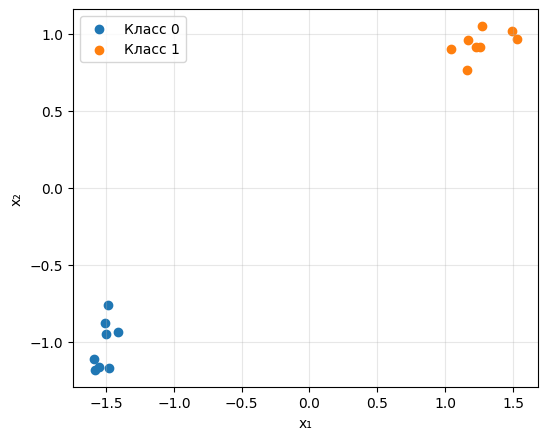

In [517]:
# посмотрим на данные
plt.figure(figsize=(6, 5))

for label in np.unique(sanity_y):
    mask = sanity_y == label
    plt.scatter(
        sanity_X[mask, 0],
        sanity_X[mask, 1],
        label=f"Класс {label}",
    )

plt.xlabel("x₁")
plt.ylabel("x₂")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [525]:
# Создание модели
hidden_pars = 8
model = make_mlp(hidden_pars, "relu")

# обучение модели
history = fit(model, sanity_X, sanity_y, sanity_X, sanity_y, epochs=10, lr=0.1, batch_size=16, shuffle_seed=SEED)
display(history)

# изменение норм матриц    
linear_layer_idx = 0
for layer in model.layers:
    if type(layer) == Linear:
        initial_fro = np.linalg.norm(layer._initialW)
        final_fro = np.linalg.norm(layer.W)
        diff_fro = np.linalg.norm(layer.W - layer._initialW)
        print(f"layer#{linear_layer_idx}: inital = ", initial_fro, "; final = ", final_fro, "; diff = ", diff_fro, sep='')
        linear_layer_idx = linear_layer_idx + 1

,epoch,train_loss,train_acc,valid_loss,valid_acc
0,0,1.3734,0.0,1.3734,0.0
1,1,0.9350,0.0,0.9350,0.0
2,2,0.6684,0.5,0.6684,0.5
3,3,0.5012,1.0,0.5012,1.0
4,4,0.3912,1.0,0.3912,1.0
5,5,0.3155,1.0,0.3155,1.0
6,6,0.2612,1.0,0.2612,1.0
7,7,0.2208,1.0,0.2208,1.0
8,8,0.1900,1.0,0.1900,1.0
9,9,0.1658,1.0,0.1658,1.0


layer#0: inital = 2.507894472673147; final = 2.528260347903508; diff = 0.293112877208045
layer#1: inital = 1.1309654439883647; final = 1.21722282626966; diff = 0.9506323245493388


In [528]:
# проверка градиентов на полной модели
def check_single_object_network():
    rng = np.random.default_rng(2026)
    first = Linear(2, 4, rng)
    last = Linear(4, 3, rng)
    model = Sequential(first, ReLU(), last)

    X = np.array([[0.4, -0.6]], dtype=np.float64)
    y = np.array([2], dtype=np.int64)

    # Задаём два активных и два неактивных нейрона.
    # Значения до ReLU находятся далеко от нуля, где нет производной.
    first.b[:] = (
        np.array([0.8, -0.7, 1.2, -1.1]) - (X @ first.W)[0]
    )

    logits = model.forward(X)
    assert logits.shape == (1, 3)

    _, dlogits = softmax_cross_entropy(logits, y)
    dx = model.backward(dlogits).copy()

    # Сохраняем аналитические градиенты до численной проверки.
    gradients = [g.copy() for g in model.gradients()]

    def objective():
        return softmax_cross_entropy(model.forward(X), y)[0]

    errors = {}
    for name, parameter, analytic in zip(
        ["W1", "b1", "W2", "b2"],
        model.parameters(),
        gradients,
    ):
        numeric = numerical_gradient(objective, parameter)
        errors[name] = compare_gradients(analytic, numeric)

    errors["X"] = compare_gradients(
        dx, numerical_gradient(objective, X)
    )
    return errors

my_check = run_checks({"Полная модель: один объект": check_single_object_network})


,проверка,статус,детали
0,Полная модель: один объект,OK,"{'W1': 1.2036021783654277e-09, 'b1': 1.138313634717306e-09, 'W2': 1.0437355263134907e-10, 'b2': 8.925319935354336e-11, 'X': 1.1222140957902711e-09}"


**Ответ:** 
1. Новый тест проверяет полную производную всей модели по входу по сравнению с конечной разностью на некотором заданном объекте, а так же производные первого слоя через (они проходят через ReLU)


## Задание 2. Исследование обучения

Используйте реализацию из задания 1. Даны два набора по 600 объектов:
гауссовские облака (`clouds`) и вложенные окружности (`circles`).
Стратифицированное разбиение на обучающую, валидационную и тестовую выборки
выполнено в пропорции 60 / 20 / 20. Параметры генерации и разбиение фиксированы.

**Протокол экспериментов.** Параметры предобработки и модели оценивайте только
по `train`, конфигурацию выбирайте по `validation`. К `test` обращайтесь
только в пункте 2.5. Во всех сравнениях сохраняйте выбранную предобработку,
число эпох и размер батча; если не оговорено иное, меняйте только исследуемый
параметр. Каждый запуск начинается с исходной инициализации.

До сравнений в пунктах 2.2–2.4 сформулируйте гипотезы. Сохраняйте настройки,
обученные модели и истории всех запусков, включая неудачные. Для завершившихся
запусков сравнивайте метрики последней эпохи. Полностью совпадающие запуски
можно использовать повторно. Заданного порога accuracy на этих данных нет.


In [529]:
def split_dataset(X: np.ndarray, y: np.ndarray) -> dict:
    idx_train, idx_hold = train_test_split(
        np.arange(len(y)), test_size=0.4, stratify=y, random_state=SEED
    )
    idx_valid, idx_test = train_test_split(
        idx_hold, test_size=0.5, stratify=y[idx_hold], random_state=SEED
    )
    assert not (
        set(idx_train) & set(idx_valid)
        or set(idx_train) & set(idx_test)
        or set(idx_valid) & set(idx_test)
    )
    result = {}
    for name, idx in [
        ("train", idx_train),
        ("valid", idx_valid),
        ("test", idx_test),
    ]:
        result[f"X_{name}"] = np.asarray(X[idx], dtype=np.float64)
        result[f"y_{name}"] = np.asarray(y[idx], dtype=np.int64)
    return result


data = {
    "clouds": split_dataset(
        *make_blobs(
            n_samples=600,
            centers=[[-2.0, -1.0], [2.0, 1.0]],
            cluster_std=0.9,
            random_state=SEED,
        )
    ),
    "circles": split_dataset(
        *make_circles(
            n_samples=600,
            factor=0.5,
            noise=0.12,
            random_state=SEED,
        )
    ),
}
for name, dataset in data.items():
    print(
        name,
        {
            part: len(dataset[f"y_{part}"])
            for part in ("train", "valid", "test")
        },
    )

# Скейлер был игрушкой, поставленной после проведения всех экспериментов на validation
from sklearn.preprocessing import StandardScaler

def scale_datasets(data):
    prepared = {}
    scalers = {}

    for name, dataset in data.items():
        scaler = StandardScaler()
        scaler.fit(dataset["X_train"])
        scalers[name] = scaler

        prepared[name] = {}
        for split in ("train", "valid", "test"):
            prepared[name][f"X_{split}"] = scaler.transform(
                dataset[f"X_{split}"]
            )
            prepared[name][f"y_{split}"] = dataset[f"y_{split}"].copy()

    return prepared, scalers

# data, _ = scale_datasets(data)

clouds {'train': 360, 'valid': 120, 'test': 120}
circles {'train': 360, 'valid': 120, 'test': 120}


### 2.1. Данные и предобработка

Для обучающей части каждого набора представьте доли классов, диапазоны
признаков, число пропусков и дубликатов, а также диаграмму рассеяния
с обозначением классов.

Выберите и обоснуйте предобработку. Подготовленные данные сохраните
в `prepared`, сохранив структуру словаря `data`. Исходный `data` не изменяйте.
Если предобработка не требуется, сохраните в `prepared` копию исходных данных.

Для каждого набора оцените на validation accuracy классификатора,
предсказывающего наиболее частый класс train. При равенстве частот выберите
класс `0`. Сопоставьте геометрию наборов с возможностями линейной модели.


In [530]:
class DummyClassifier:
    def __init__(self, X_train, y_train):
        values, counts = np.unique(y_train, return_counts=True)
        self.result = values[counts.argmax()]

    def forward(self, X):
        return np.ones(X.shape[0]) * self.result



,набор,класс,число объектов,доля
0,clouds,0,180,0.5
1,clouds,1,180,0.5


,набор,признак,минимум,максимум,пропуски
0,clouds,x1,-4.9171,4.3160,0
1,clouds,x2,-2.9900,3.3691,0


,набор,число объектов,пропуски в X,пропуски в y,дубликаты X,"дубликаты (X, y)"
0,clouds,360,0,0,0,0


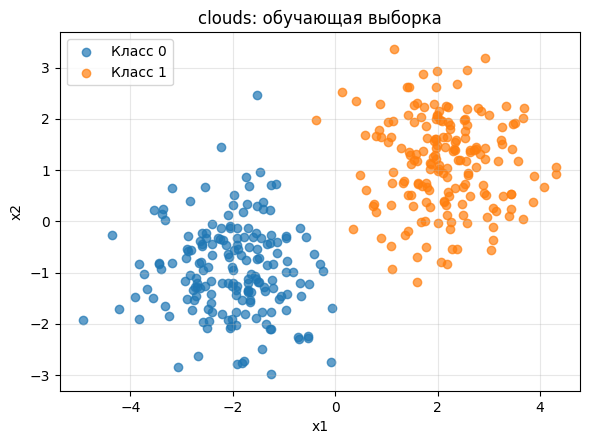

,набор,класс,число объектов,доля
0,circles,0,180,0.5
1,circles,1,180,0.5


,набор,признак,минимум,максимум,пропуски
0,circles,x1,-1.2049,1.1147,0
1,circles,x2,-1.1999,1.2900,0


,набор,число объектов,пропуски в X,пропуски в y,дубликаты X,"дубликаты (X, y)"
0,circles,360,0,0,0,0


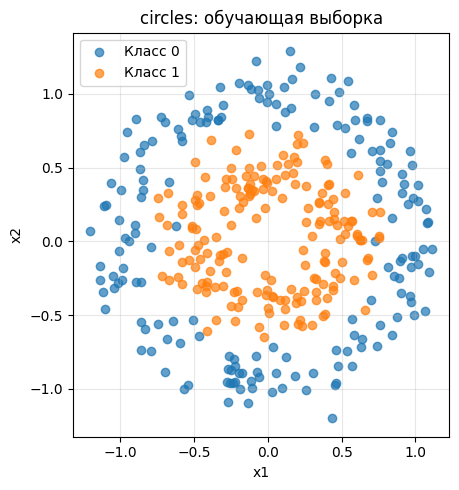

In [531]:
def analyse(X, y, name):
    X = np.asarray(X)
    y = np.asarray(y)

    if X.ndim != 2 or X.shape[1] < 2:
        raise ValueError("X должен быть матрицей минимум с двумя признаками.")
    if y.shape != (len(X),) or len(X) == 0:
        raise ValueError("Нужна непустая выборка с одной меткой на объект.")

    features = pd.DataFrame(
        X, columns=[f"x{i + 1}" for i in range(X.shape[1])]
    )

    # Число объектов и доля каждого класса.
    counts = pd.Series(y).value_counts().sort_index()
    classes = pd.DataFrame({
        "набор": name,
        "класс": counts.index,
        "число объектов": counts.to_numpy(),
        "доля": counts.to_numpy() / len(y),
    })

    # Минимумы и максимумы считаются без учёта пропусков.
    ranges = pd.DataFrame({
        "набор": name,
        "признак": features.columns,
        "минимум": features.min().to_numpy(),
        "максимум": features.max().to_numpy(),
        "пропуски": features.isna().sum().to_numpy(),
    })

    labeled = features.assign(target=y)
    quality = pd.DataFrame({
        "набор": [name],
        "число объектов": [len(X)],
        "пропуски в X": [int(features.isna().sum().sum())],
        "пропуски в y": [int(pd.isna(y).sum())],
        "дубликаты X": [int(features.duplicated().sum())],
        "дубликаты (X, y)": [int(labeled.duplicated().sum())],
    })

    display(classes)
    display(ranges)
    display(quality)

    fig, ax = plt.subplots(figsize=(6, 5))
    for label in counts.index:
        mask = y == label
        ax.scatter(
            X[mask, 0], X[mask, 1],
            label=f"Класс {label}",
            alpha=0.7,
        )

    ax.set(
        title=f"{name}: обучающая выборка",
        xlabel="x1",
        ylabel="x2",
    )
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_aspect("equal")
    fig.tight_layout()
    plt.show()

    return {"classes": classes, "ranges": ranges, "quality": quality}

for name in data.keys():
    analyse(data[name]["X_train"], data[name]["y_train"], name)


In [532]:
prepared = data.copy()

In [533]:
# оценка accuracy для DummyClassifier
baselines = {}
base_predicts = {}
base_acc = {}
for name in prepared.keys():
    baselines[name] = DummyClassifier(prepared[name]["X_train"], prepared[name]["y_train"])
    base_predicts[name] = baselines[name].forward(prepared[name]["X_valid"])
    base_acc[name] = np.sum(base_predicts[name] == prepared[name]["y_valid"]) / prepared[name]["y_valid"].shape[0]

print("Accuracy for baseline:", base_acc)


Accuracy for baseline: {'clouds': 0.5, 'circles': 0.5}


**Ответ:**

1. Для линейной модели первые данные идеальны, поскольку выборка линейно разделима, вторая -- гроб.
2. Предобработку не стал делать, так как данные "хорошо обусловлены" в терминах среднего и диспрерсии по обоим признакам. Конечно, можно сделать переход в полярные координаты для второй выборки, но тогда пропадет смысл задачи: будут два одинаковых датасета
3. Baseline ожидаемо предсказывает 50%


Функция `plot_boundary` строит разделяющую границу модели, обучающие объекты
и ошибки на validation. Аргументы должны быть представлены в той же шкале,
в которой обучалась модель.


In [584]:
def plot_boundary(
    model: Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_valid: np.ndarray,
    y_valid: np.ndarray,
    title: str,
):
    low, high = X_train.min(axis=0) - 0.4, X_train.max(axis=0) + 0.4
    xx, yy = np.meshgrid(
        np.linspace(low[0], high[0], 300), np.linspace(low[1], high[1], 300)
    )
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    grid_logits = model.forward(grid)
    score = (grid_logits[:, 1] - grid_logits[:, 0]).reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6, 5))
    if score.min() < 0 < score.max():
        ax.contour(xx, yy, score, levels=[0.0], linewidths=1.6)
    for label, marker in [(0, "o"), (1, "s")]:
        mask = y_train == label
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            marker=marker,
            s=18,
            alpha=0.5,
            label=f"train: класс {label}",
        )
    wrong = model.forward(X_valid).argmax(axis=1) != y_valid
    if np.any(wrong):
        ax.scatter(
            X_valid[wrong, 0],
            X_valid[wrong, 1],
            marker="x",
            s=42,
            label="ошибка validation",
        )
        print("X for wrong", X_valid[wrong, :], sep='\n')
    ax.set(
        title=title,
        xlabel="x1 (рабочая шкала)",
        ylabel="x2 (рабочая шкала)",
        xlim=(low[0], high[0]),
        ylim=(low[1], high[1]),
    )
    ax.legend()
    fig.tight_layout()
    plt.show()

### 2.2. Линейная модель и сеть со скрытым слоем

На каждом наборе обучите линейный классификатор `make_linear()` и сеть
`make_mlp(hidden=16)` с ReLU — всего четыре модели.
Используйте `seed=SEED`, `shuffle_seed=SHUFFLE_SEED` и единый режим обучения:
`epochs=200`, `lr=0.1`, `batch_size=32`.

Представьте таблицу train/validation loss и accuracy для четырёх моделей.
Для окружностей постройте кривые train/validation loss и разделяющие границы
обеих моделей.

Объясните различия результатов с учётом геометрии данных, выразительности
моделей и хода оптимизации.


**Гипотеза:** линейная модель ок только на линейно разделимой выборке, нейронка ок верзде


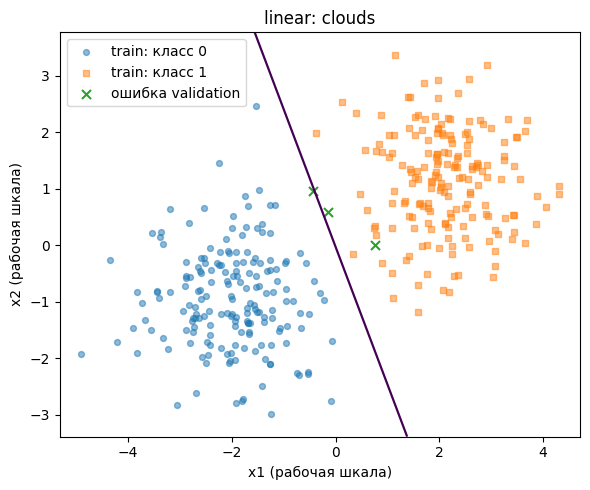

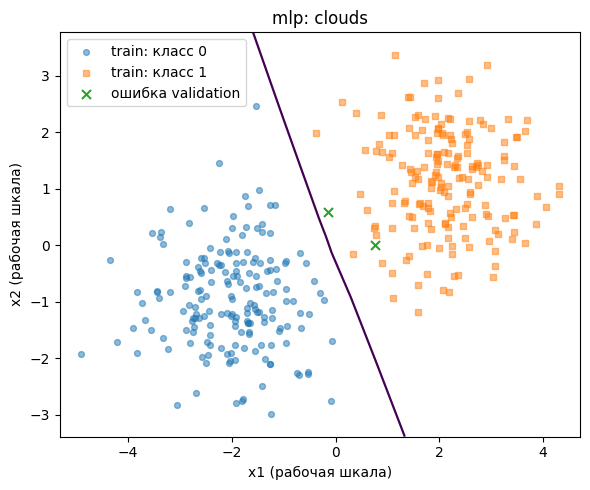

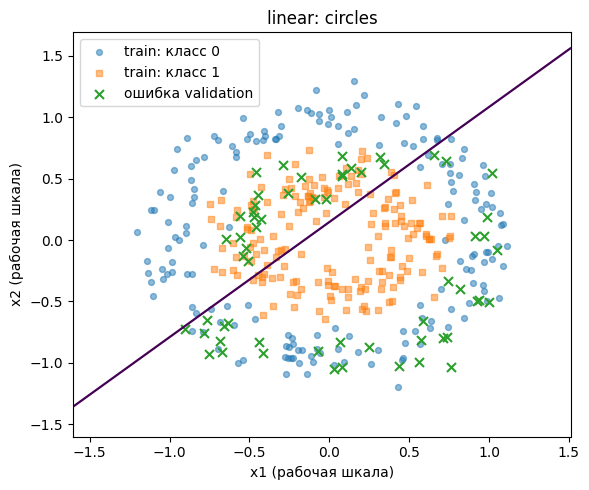

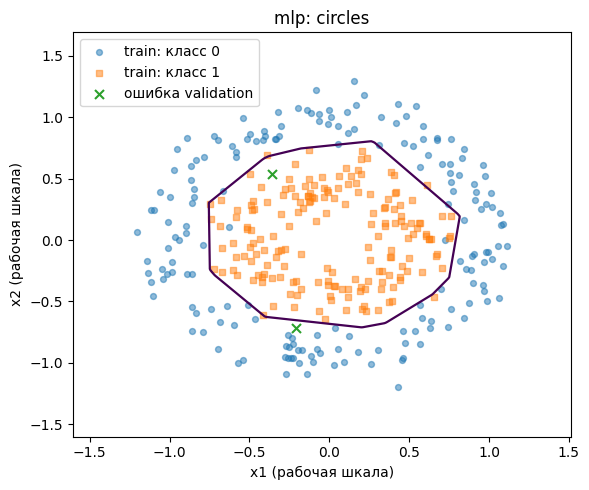

In [538]:
linear_classifier = {}
linear_history = {}
mlp = {}
mpl_history = {}

# создаем и учим модели (если учить 2000 эпох, то линейная модель допускает две ошибки на validation, а не три)
epoch = 200
for name in prepared.keys():
    linear_classifier[name] = make_linear()
    mlp[name] = make_mlp(hidden=16)
    X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
    X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
    linear_history[name] = fit(linear_classifier[name], X_train, y_train, X_valid, y_valid, epochs=epoch, lr=0.1, batch_size=32, shuffle_seed=SHUFFLE_SEED)
    mpl_history[name] = fit(mlp[name], X_train, y_train, X_valid, y_valid, epochs=epoch, lr=0.1, batch_size=32, shuffle_seed=SHUFFLE_SEED)

    plot_boundary(linear_classifier[name], X_train, y_train, X_valid, y_valid, "linear: " + name)
    plot_boundary(mlp[name], X_train, y_train, X_valid, y_valid, "mlp: " + name)

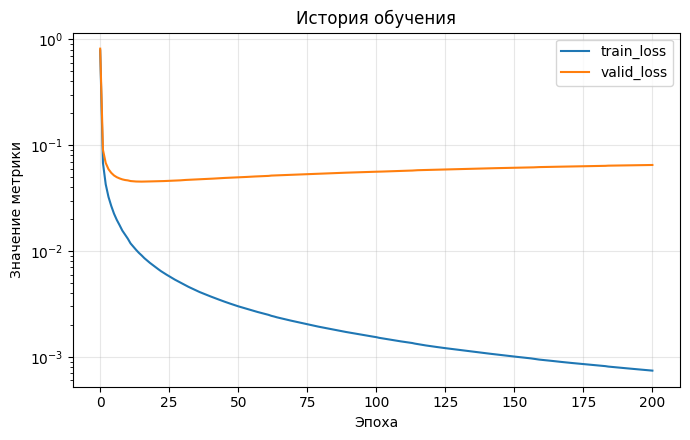

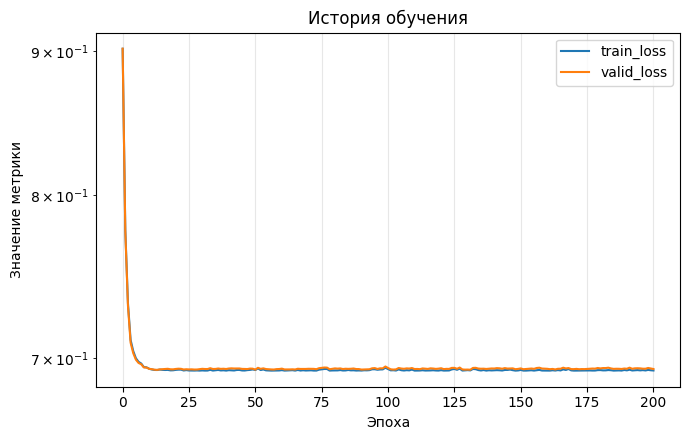

In [539]:
def plot_history(history, params):
    # Можно передать одно имя или список имён столбцов.
    if isinstance(params, str):
        params = [params]

    fig, ax = plt.subplots(figsize=(7, 4.5))

    for param in params:
        ax.plot(history["epoch"], history[param], label=param)

    ax.set(
        title="История обучения",
        xlabel="Эпоха",
        ylabel="Значение метрики",
    )
    ax.legend()
    ax.grid(alpha=0.3)
    # ax.set_xscale('log')
    ax.set_yscale('log')
    fig.tight_layout()
    plt.show()
    
plot_history(mpl_history["clouds"], ["train_loss", "valid_loss"])
plot_history(linear_history["circles"], ["train_loss", "valid_loss"])

In [540]:
# таблицы train/validation
train_data = {}
validation_data = {}
loss_train_data = {}
loss_validation_data = {}

for name in prepared.keys():
    X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
    X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
    # acc
    validation_data["linear: " + name] = np.sum(np.argmax(linear_classifier[name].forward(X_valid), axis=1) == y_valid) / y_valid.shape[0]
    train_data["linear: " + name] = np.sum(np.argmax(linear_classifier[name].forward(X_train), axis=1) == y_train) / y_train.shape[0]
    validation_data["mlp: " + name] = np.sum(np.argmax(mlp[name].forward(X_valid), axis=1) == y_valid) / y_valid.shape[0]
    train_data["mlp: " + name] = np.sum(np.argmax(mlp[name].forward(X_train), axis=1) == y_train) / y_train.shape[0]
    # loss
    loss_validation_data["linear: " + name], _ = softmax_cross_entropy(linear_classifier[name].forward(X_valid), y_valid)
    loss_train_data["linear: " + name], _ = softmax_cross_entropy(linear_classifier[name].forward(X_train), y_train)
    loss_validation_data["mlp: " + name], _ = softmax_cross_entropy(mlp[name].forward(X_valid), y_valid)
    loss_train_data["mlp: " + name], _ = softmax_cross_entropy(mlp[name].forward(X_train), y_train)


print("Accuracy для разных моделей и сетов")
acc = pd.concat([pd.DataFrame([train_data], index=["train"]), pd.DataFrame([validation_data], index=["valid"])], axis=0)
display(acc)
print("Loss для разных моделей и сетов")
loss = pd.concat([pd.DataFrame([loss_train_data], index=["train"]), pd.DataFrame([loss_validation_data], index=["valid"])], axis=0)
display(loss)

Accuracy для разных моделей и сетов


,linear: clouds,mlp: clouds,linear: circles,mlp: circles
train,1.000,1.0000,0.5028,0.9861
valid,0.975,0.9833,0.5083,0.9833


Loss для разных моделей и сетов


,linear: clouds,mlp: clouds,linear: circles,mlp: circles
train,0.0034,0.0007,0.6930,0.0705
valid,0.0493,0.0651,0.6938,0.0674


**Обсуждение результатов:** гипотеза подтвердилась


### 2.3. Ширина сети и шаг обучения

На наборе `circles` исследуйте сеть с ReLU в двух последовательных сериях.
Используйте `seed=SEED`, `shuffle_seed=SHUFFLE_SEED`, `epochs=200`
и `batch_size=32`.

**Серия A.** Сравните ширины скрытого слоя `4, 16, 64` при `lr=0.1`.
Постройте зависимость конечных train/validation loss от ширины и выберите
ширину по validation.

**Серия B.** Для выбранной ширины сравните шаги `0.01, 0.1, 0.5`.
Начальные параметры и порядок батчей должны совпадать во всех трёх запусках.
Постройте кривые train/validation loss по эпохам и выберите шаг по validation.

Сведите настройки и конечные метрики двух серий в общую таблицу.
Всего в сериях пять различных конфигураций; совпадающий запуск из пункта 2.2
можно использовать повторно. Расходящиеся запуски отметьте отдельно;
при необходимости допустим один дополнительный диагностический запуск.

Обсудите влияние ширины и шага на результаты. Обоснуйте, позволяют ли
наблюдения судить о недообучении, переобучении и устойчивости оптимизации.


**Серия A. Гипотеза:**

С увеличением ширины модель становится "более обобщающей", более того, модель меньшей ширины включена в модель большей ширины (можно занулить строки в матрице и векторе параметров и получить меньшую модель), так что результаты должна быть "монотонны по ширине скрытого слоя"  


In [541]:
# Серия A.
hidden_array = [4, 9, 16, 25, 36, 49, 64, 100, 225]
networks_per_hidden = {}
history_for_hidden = {}
results_for_hidden_test = pd.DataFrame()
name = "circles"
for hidden_params in hidden_array:
    # data
    X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
    X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
    # creation
    networks_per_hidden[hidden_params] = make_mlp(hidden=hidden_params)
    # fitting
    history_for_hidden[hidden_params] = fit(networks_per_hidden[hidden_params], X_train, y_train, X_valid, y_valid)
    # computing results
    cur_res = history_for_hidden[hidden_params].iloc[-1].copy().to_frame()
    cur_res.columns = ["hidden = " + str(hidden_params)]
    results_for_hidden_test = pd.concat([results_for_hidden_test, cur_res], axis=1)

display(results_for_hidden_test)

,hidden = 4,hidden = 9,hidden = 16,hidden = 25,hidden = 36,hidden = 49,hidden = 64,hidden = 100,hidden = 225
epoch,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000
train_loss,0.0877,0.0800,0.0705,0.0711,0.0674,0.0660,0.0646,0.0618,0.0582
train_acc,0.9694,0.9750,0.9861,0.9778,0.9778,0.9806,0.9861,0.9833,0.9833
valid_loss,0.0911,0.0630,0.0674,0.0678,0.0635,0.0656,0.0613,0.0661,0.0614
valid_acc,0.9583,0.9917,0.9833,0.9833,0.9833,0.9833,0.9833,0.9833,0.9833


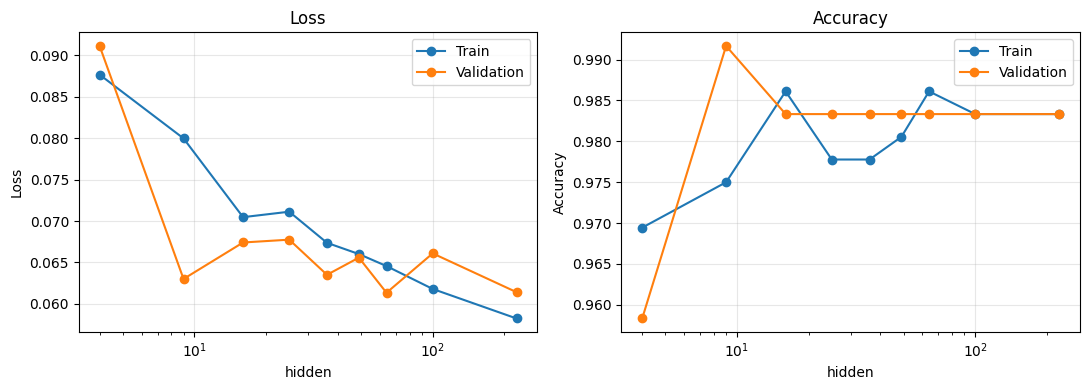

In [542]:
# plotting curves by hidder layers params count
hidden = [int(col.split("=")[1].strip()) for col in results_for_hidden_test.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for ax, metric, title in zip(
    axes, ["loss", "acc"], ["Loss", "Accuracy"]
):
    ax.plot(hidden, results_for_hidden_test.loc[f"train_{metric}"], "o-", label="Train")
    ax.plot(hidden, results_for_hidden_test.loc[f"valid_{metric}"], "o-", label="Validation")

    ax.set(title=title, xlabel="hidden", ylabel=title)
    ax.set_xticks(hidden)
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_xscale('log')

fig.tight_layout()
plt.show()

In [571]:
selected_width = 9

**Серия B. Выбор ширины и гипотеза:**

1. Для очень маленьких learning rates не будет достаточно такого количества эпох, которых достаточно для более больших шагов: думаю, что нужно сравнивать на обратно пропорционально изменяющемся количестве эпох. С другой стороны будет разная вычисилтельная сложность тогда в модели, так что наверное мы хотим фиксированную стоимость по времени.
2. По lr у всех метрик будет U-образная кривая, так как метод с постоянным шагом может разваливаться при очень большом шаге, а при очень маленьком просто не доходить до локального минимума

In [572]:
# Серия B.
step_array = [1e-4, 1e-3, 0.01, 0.08, 0.1, 0.2, 0.5, 1, 2, 4]
networks_per_step = {}
history_for_step = {}
results_for_step_test = pd.DataFrame()
name = "circles"
for step in step_array:
    # data
    X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
    X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
    # creation
    networks_per_step[step] = make_mlp(hidden=selected_width)
    # fitting
    history_for_step[step] = fit(networks_per_step[step], X_train, y_train, X_valid, y_valid, lr=step)
    # computing results
    cur_res = history_for_step[step].iloc[-1].copy().to_frame()
    cur_res.columns = ["step = " + str(step)]
    results_for_step_test = pd.concat([results_for_step_test, cur_res], axis=1)

display(results_for_step_test)

,step = 0.0001,step = 0.001,step = 0.01,step = 0.08,step = 0.1,step = 0.2,step = 0.5,step = 1,step = 2,step = 4
epoch,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000,200.0000
train_loss,0.7045,0.6850,0.4572,0.0865,0.0800,0.0772,0.2305,0.0599,0.0624,0.8257
train_acc,0.5500,0.4806,0.9361,0.9750,0.9750,0.9694,0.9361,0.9806,0.9778,0.5000
valid_loss,0.7036,0.6827,0.4505,0.0691,0.0630,0.0531,0.1753,0.0605,0.0511,0.8257
valid_acc,0.5667,0.4667,0.9500,0.9833,0.9917,0.9917,0.9333,0.9750,0.9750,0.5000


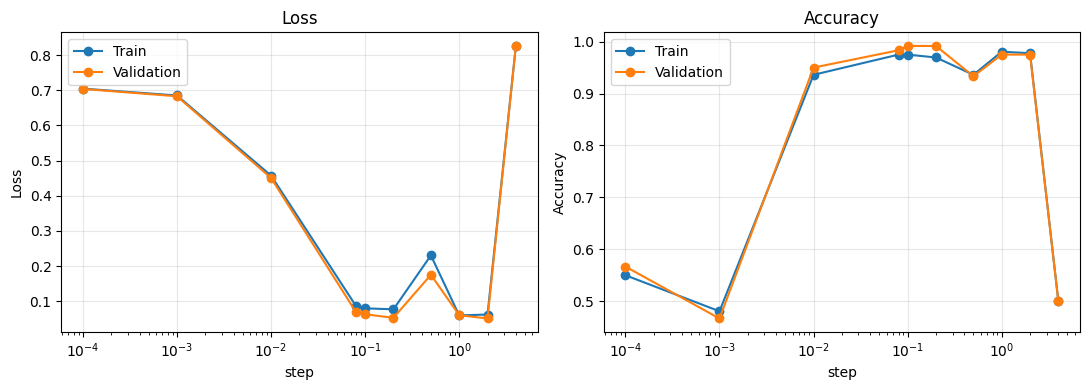

In [573]:
# Тут график по финальному accuracy и loss в зависимости от шага 
steps = [float(col.split("=")[1].strip()) for col in results_for_step_test.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for ax, metric, title in zip(
    axes, ["loss", "acc"], ["Loss", "Accuracy"]
):
    ax.plot(steps, results_for_step_test.loc[f"train_{metric}"], "o-", label="Train")
    ax.plot(steps, results_for_step_test.loc[f"valid_{metric}"], "o-", label="Validation")

    ax.set(title=title, xlabel="step", ylabel=title)
    ax.set_xticks(steps)
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_xscale('log')

fig.tight_layout()
plt.show()

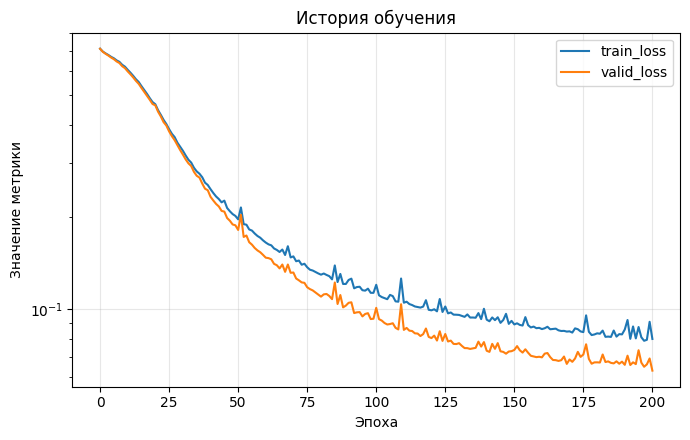

In [574]:
# Кривая loss по эпохам по train и validation
step_under_analysis = 0.1
plot_history(history_for_step[step_under_analysis], ["train_loss", "valid_loss"])

In [575]:
selected_lr = 0.1

**Обсуждение результатов и выбранные настройки:**

1. Для серии с шириной я сделал чуть больше тестов, оказалось выигрышной ширина равной 9. Данные оказались не мотононными, но "с видимой тенденцией". Немнотонность получается из-за того, что модель в результате оптимизации сходится не в одно и то же место, но меньшая модель имеет меньше шансов сойтись в более хороший минимум. Стоит конечно сделать мультистарт для SGD и посмотреть как он будет себя вести. Ещё лучше запускать более большую модель с точки минимума меньшей модели, предварительно расширив матрицы до нужного размера, однако и в этом случае монотонность не гарактируется, поскольку метод SGD не является монотонным (в нашей реализации)
2. Гипотеза подтвердилась, выбранный lr=0.1, графики loss от номера эпохи на больших шагах свидетельствуют о неуствойчивой остимизации (метод почти что разваливается и увеличивает loss). Переобучения на validation не замечено.


### 2.4. Функция активации и обучение скрытого слоя

Сравните ReLU с предоставленной пороговой активацией `Step`:

$$
\operatorname{Step}(x) =
\begin{cases}
1, & x > 0, \\
0, & x \leq 0.
\end{cases}
$$

В её обратном проходе используется нулевая производная; в точке разрыва
это соглашение реализации. Реализацию `Step` изменять нельзя.
Используйте `circles` и выбранные в пункте 2.3 ширину и шаг обучения.

**Диагностика одного обновления.** Создайте сети с ReLU и Step при `seed=SEED`.
Начальные параметры должны попарно совпадать по значениям, но храниться
в независимых массивах. Выполните по одному шагу SGD на первых 32 объектах
train в порядке хранения. Для каждой сети представьте loss до и после шага,
нормы градиентов `W1`, `b1`, `W2`, `b2` перед обновлением
и нормы изменения этих параметров после обновления.

**Полное обучение.** Обучите обе архитектуры заново для инициализаций
`42, 43, 44` — всего шесть запусков. В каждой паре начальные параметры
должны совпадать. Шаг, ширина, число эпох, размер и порядок батчей одинаковы
во всех запусках; отдельно настраивать Step не требуется.

Представьте:

- таблицу train/validation loss и accuracy всех шести запусков и норм
  изменения матрицы весов первого слоя;
- среднее и выборочное стандартное отклонение validation accuracy
  по трём инициализациям для каждой активации (`ddof=1`);
- кривые train/validation loss и разделяющие границы двух моделей
  с `seed=SEED`.

Объясните связь между градиентами, изменением параметров и качеством моделей.
Оцените чувствительность результатов к инициализации и сформулируйте
ограничения сравнения активаций при общем режиме обучения.


In [504]:
class Step(Module):
    """Пороговая активация с нулевым градиентом в обратном проходе."""

    def forward(self, X: np.ndarray) -> np.ndarray:
        return (X > 0).astype(np.float64)

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        return np.zeros_like(grad_output)

**Гипотеза:** с функцией Step первый слой просто не будет обучаться, потому что градиент не пройдет через функцию Хевисайда. Получается, что ожидаем обучение только второго слоя, а первый слой + Хевисайд есть фиксированное преобразование признаков. Таким образом, мы редуцируемся до линейной модели, которая сможет решить только линейно разделимую выборку.


In [576]:
# Диагностика одного обновления.
pass

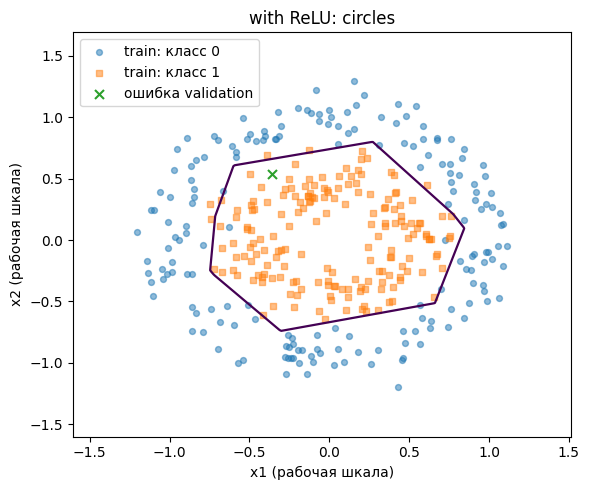

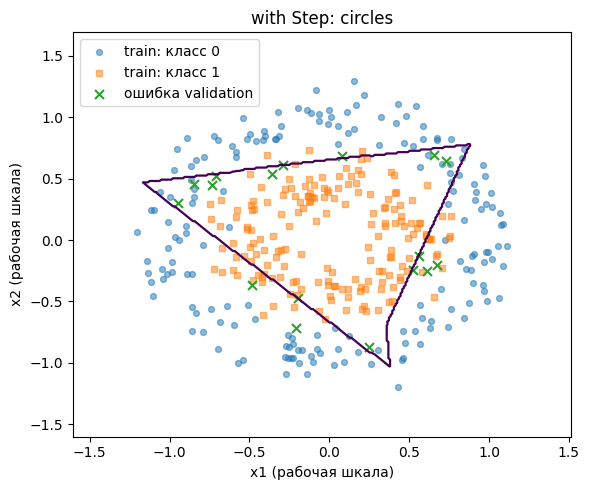

Lin->ReLU->Lin


,initial = 41,initial = 42,initial = 43
epoch,200.0000,200.0000,200.0000
train_loss,0.0737,0.0800,0.0768
train_acc,0.9806,0.9750,0.9806
valid_loss,0.0727,0.0630,0.0700
valid_acc,0.9833,0.9917,0.9833


Lin->Step->Lin


,initial = 41,initial = 42,initial = 43
epoch,200.0000,200.0000,200.0000
train_loss,0.4433,0.3613,0.3818
train_acc,0.7750,0.8639,0.8333
valid_loss,0.4030,0.3880,0.3299
valid_acc,0.7750,0.8583,0.8667


In [577]:
# Сравнение активаций по трём инициализациям.
initial_seed = [41, SEED, 43]
nw_by_initial = {}
stepnw_by_initial = {}
nw_histroy_by_initial = {}
stepnw_history_by_initial = {}
nw_results_by_initial = pd.DataFrame()
stepnw_results_by_initial = pd.DataFrame()
name = "circles"
for seed in initial_seed:
    # data
    X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
    X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
    # creation
    nw_by_initial[seed] = make_mlp(hidden=selected_width, seed=seed)
    stepnw_by_initial[seed] = make_mlp(hidden=selected_width, seed=seed, activation="step")
    # fitting
    nw_histroy_by_initial[seed] = fit(nw_by_initial[seed], X_train, y_train, X_valid, y_valid, lr=selected_lr)
    stepnw_history_by_initial[seed] = fit(stepnw_by_initial[seed], X_train, y_train, X_valid, y_valid, lr=selected_lr)
    # computing results
    nw_cur_res = nw_histroy_by_initial[seed].iloc[-1].copy().to_frame()
    nw_cur_res.columns = ["initial = " + str(seed)]
    stepnw_cur_res = stepnw_history_by_initial[seed].iloc[-1].copy().to_frame()
    stepnw_cur_res.columns = ["initial = " + str(seed)]

    nw_results_by_initial = pd.concat([nw_results_by_initial, nw_cur_res], axis=1)
    stepnw_results_by_initial = pd.concat([stepnw_results_by_initial, stepnw_cur_res], axis=1)

    # разедялюище поверхности только для seed=SEED
    if seed==SEED:
        plot_boundary(nw_by_initial[seed], X_train, y_train, X_valid, y_valid, "with ReLU: " + name)
        plot_boundary(stepnw_by_initial[seed], X_train, y_train, X_valid, y_valid, "with Step: " + name)

print("Lin->ReLU->Lin")
display(nw_results_by_initial)
print("Lin->Step->Lin")
display(stepnw_results_by_initial)


In [578]:
# отклонения в accuracy
valid_acc = pd.DataFrame({
    "ReLU": nw_results_by_initial.loc["valid_acc"],
    "Step": stepnw_results_by_initial.loc["valid_acc"],
}).astype(float)

summary = pd.DataFrame({
    "среднее valid_acc": valid_acc.mean(axis=0),
    "выборочное std valid_acc": valid_acc.std(axis=0, ddof=1),
})
display(summary)

# argmax по accuracy
acc = nw_results_by_initial.loc["valid_acc"]

best_acc = acc.max()       # максимальная validation accuracy
best_run = acc.idxmax()    # название столбца лучшего запуска

print(best_run, "; best acc = ", best_acc)

,среднее valid_acc,выборочное std valid_acc
ReLU,0.9861,0.0048
Step,0.8333,0.0507


initial = 42 ; best acc =  0.9916666666666667


,набор,класс,число объектов,доля
0,"circles: Linear + Step, seed=42, проекция PCA",0,180,0.5
1,"circles: Linear + Step, seed=42, проекция PCA",1,180,0.5


,набор,признак,минимум,максимум,пропуски
0,"circles: Linear + Step, seed=42, проекция PCA",x1,-1.4843,1.0177,0
1,"circles: Linear + Step, seed=42, проекция PCA",x2,-1.0657,1.0682,0


,набор,число объектов,пропуски в X,пропуски в y,дубликаты X,"дубликаты (X, y)"
0,"circles: Linear + Step, seed=42, проекция PCA",360,0,0,329,319


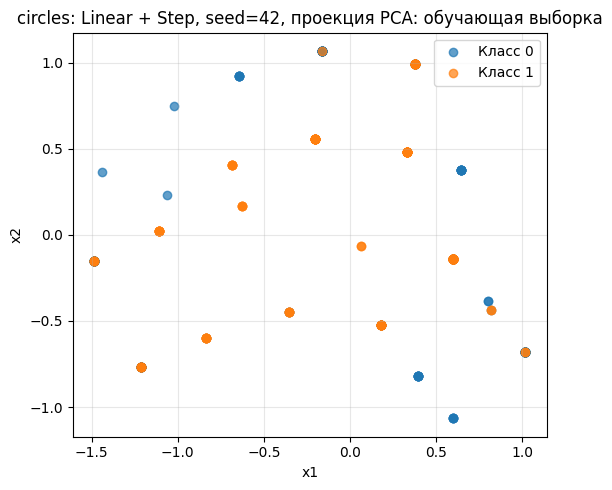

In [579]:
# to plot new features after Linear + Step
from sklearn.decomposition import PCA

def plot_step_features(name, seed=SEED, type = "train"):
    X_train = prepared[name]["X_" + type]
    y_train = prepared[name]["y_" + type]

    # Используем Linear и Step из сохранённой модели без переобучения.
    model = stepnw_by_initial[seed]
    feature_extractor = Sequential(*model.layers[:2])
    new_features = feature_extractor.forward(X_train)

    # Все скрытые признаки бинарные; PCA нужна только для графика на плоскости.
    # Оси x1 и x2 в analyse здесь обозначают первую и вторую компоненты PCA.
    projected = PCA(n_components=2, svd_solver="full").fit_transform(new_features)
    analyse(
        projected, y_train,
        f"{name}: Linear + Step, seed={seed}, проекция PCA",
    )

    # Возвращаем исходные h признаков, а не их двумерную проекцию.
    return new_features


name = "circles"  # Или "clouds".
new_features = plot_step_features(name, SEED, "train")

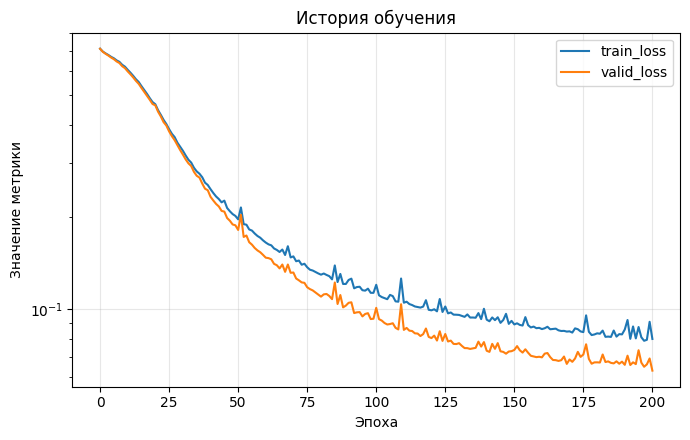

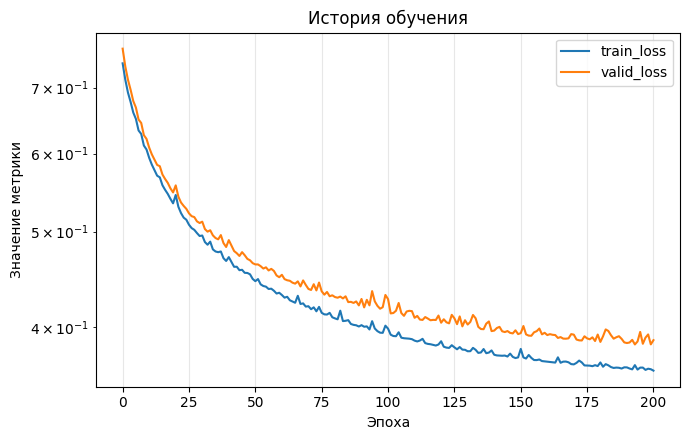

In [580]:
plot_history(nw_histroy_by_initial[SEED], ["train_loss", "valid_loss"])
plot_history(stepnw_history_by_initial[SEED], ["train_loss", "valid_loss"])

**Обсуждение результатов:**

1. Модель с ReLU ведет себя как и в пердыдущих экспериментах, более-менее одинаково. В целом, её поведение можно трактовать как SVM с некотором новым пространством признаков конечной размерности, так что тут ничего удивительного.
2. Модель со Step делает глупую вещь: происходит случайное преобразование параметров, да ещё и так, что многие классы просто накладываются друг на друга, и их невозможно отделить, потому что они буквально находятся в одной и той же точке. Так происходит даже для набора clouds. Ну а после делается линейная модель, которая строит гиперплоскость. Классная модель со случайным преобразованием параметров, чтож, она сильно зависит от начального приближения.

### 2.5. Итоговая оценка

По результатам пунктов 2.2–2.4 выберите одну из конфигураций сети со скрытым
слоем для `circles`. До обращения к test зафиксируйте архитектуру,
предобработку и режим обучения, обоснуйте выбор. Используйте сохранённую
модель с `seed=SEED`. Линейный классификатор из пункта 2.2 служит базовой моделью.

Оцените обе модели на test набора `circles`. Представьте таблицу из двух строк
с настройками, validation loss/accuracy выбранных запусков и test loss/accuracy.
После просмотра test конфигурации не меняйте; дообучение на train + validation
не предусмотрено. Тестовая часть `clouds` в работе не используется.

Разберите 3–5 ошибок выбранной сети: приведите координаты объектов, истинные
и предсказанные классы либо отметьте ошибки на диаграмме. Если ошибок меньше,
покажите все; если их нет, укажите это явно.

Сопоставьте итоговую оценку с выводами предыдущих экспериментов. Укажите
ограничение проведённого исследования и предложите следующий эксперимент,
не выполняя его.


**Выбранная конфигурация и обоснование:**

1. Модель с ReLU, lr = 1e-1, hidden = 9, epochs = 200, инициализация с seed=SEED далет лучшее решение
2. Обоснование просто по валидационной выборке в предыдущих экспериментах



In [ ]:
name = 'circles'
production_model = make_mlp(hidden=selected_width, activation='relu', seed=SEED)
base_model = linear_classifier[name]

# учим обе модели
X_train, y_train = prepared[name]["X_train"], prepared[name]["y_train"]
X_valid, y_valid = prepared[name]["X_valid"], prepared[name]["y_valid"]
# fitting
nw_history = fit(production_model, X_train, y_train, X_valid, y_valid, lr=selected_lr)
base_history = fit(base_model, X_train, y_train, X_valid, y_valid, lr=selected_lr)
# computing results
nw_cur_res = nw_history.iloc[-1].copy().to_frame()
nw_cur_res.columns = ["network"]

base_cur_res = stepnw_history_by_initial[seed].iloc[-1].copy().to_frame()
base_cur_res.columns = ["baseline"]
total_results = pd.concat([nw_cur_res, base_cur_res], axis=1)

display(total_results)
 

,network,baseline
epoch,200.0000,200.0000
train_loss,0.0800,0.3818
train_acc,0.9750,0.8333
valid_loss,0.0630,0.3299
valid_acc,0.9917,0.8667


In [503]:
# Итоговая оценка моделей на test
X_test, y_test = prepared[name]["X_test"], prepared[name]["y_test"]
base_test_results = evaluate(base_model, X_test, y_test)
nw_test_results = evaluate(production_model, X_test, y_test)

print(base_test_results)
print(nw_test_results)

{'loss': 0.694559872493074, 'acc': 0.475}
{'loss': 0.06172988465542772, 'acc': 0.9916666666666667}


X for wrong
[[-0.48017094  0.52720617]]


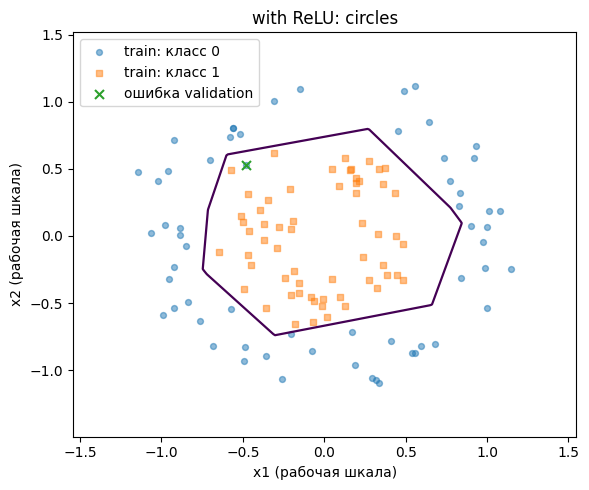

In [585]:
# разделяющая поверхность и ошибки на тесте
plot_boundary(production_model, X_test, y_test, X_test, y_test, "with ReLU: " + name)

**Обсуждение результатов:**

1. Модель дает одну ошибку -- она вылезла за ди
